In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

print("Python:", sys.version)
print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Python executable: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\.venv\Scripts\python.exe
NumPy: 2.4.6
Pandas: 3.1.1
OpenCV: 5.0.0


In [3]:
from pathlib import Path

current_dir = Path.cwd()

if (current_dir / "datasets").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "datasets").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Could not locate the datasets folder.")

HANDWRITING_PATH = PROJECT_ROOT / "datasets" / "handwriting"
WHITEBOARD_PATH = PROJECT_ROOT / "datasets" / "whiteboard"

print("Project root:", PROJECT_ROOT)
print("Handwriting dataset:", HANDWRITING_PATH)
print("Whiteboard dataset:", WHITEBOARD_PATH)

Project root: c:\Users\rohit\OneDrive\Desktop\BoardMindAI
Handwriting dataset: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\datasets\handwriting
Whiteboard dataset: c:\Users\rohit\OneDrive\Desktop\BoardMindAI\datasets\whiteboard


In [4]:
import pandas as pd

train_df = pd.read_parquet(HANDWRITING_PATH / "train.parquet")
val_df = pd.read_parquet(HANDWRITING_PATH / "validation.parquet")
test_df = pd.read_parquet(HANDWRITING_PATH / "test.parquet")

print("TRAINING DATA:", len(train_df))
print("VALIDATION DATA:", len(val_df))
print("TEST DATA:", len(test_df))

total = len(train_df) + len(val_df) + len(test_df)

print("\nTOTAL IMAGES:", total)

print("\nDATASET SPLIT PERCENTAGES:")
print(f"Train: {len(train_df)/total*100:.2f}%")
print(f"Validation: {len(val_df)/total*100:.2f}%")
print(f"Test: {len(test_df)/total*100:.2f}%")

print("\nCOLUMNS:")
print(train_df.columns.tolist())

TRAINING DATA: 6482
VALIDATION DATA: 976
TEST DATA: 2915

TOTAL IMAGES: 10373

DATASET SPLIT PERCENTAGES:
Train: 62.49%
Validation: 9.41%
Test: 28.10%

COLUMNS:
['text', 'image']


In [5]:
sample = train_df.iloc[0]

print("Transcription:", sample["text"])
print("Image field type:", type(sample["image"]))

if isinstance(sample["image"], dict):
    print("Image keys:", sample["image"].keys())

Transcription: put down a resolution on the subject
Image field type: <class 'dict'>
Image keys: dict_keys(['bytes', 'path'])


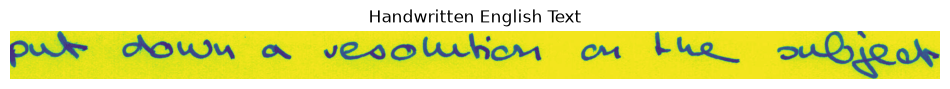

Actual text: put down a resolution on the subject


In [6]:
from PIL import Image
from io import BytesIO

image_data = train_df.iloc[0]["image"]

if isinstance(image_data, dict):
    if image_data.get("bytes") is not None:
        image = Image.open(BytesIO(image_data["bytes"]))
    else:
        image = Image.open(image_data["path"])
else:
    raise TypeError("Unexpected image format. Inspect the image field.")

plt.figure(figsize=(12, 3))
plt.imshow(image)
plt.axis("off")
plt.title("Handwritten English Text")
plt.show()

print("Actual text:", train_df.iloc[0]["text"])

In [7]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

splits = ["train", "valid", "test"]

whiteboard_counts = {}

for split in splits:
    image_dir = WHITEBOARD_PATH / split / "images"

    if not image_dir.exists():
        print(f"Missing folder: {image_dir}")
        continue

    images = [
        file for file in image_dir.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    whiteboard_counts[split] = len(images)

total_images = sum(whiteboard_counts.values())

print("WHITEBOARD DATASET")
print("------------------")

for split, count in whiteboard_counts.items():
    percentage = count / total_images * 100 if total_images else 0
    print(f"{split}: {count} images ({percentage:.2f}%)")

print("------------------")
print("Total:", total_images)

WHITEBOARD DATASET
------------------
train: 1608 images (81.87%)
valid: 179 images (9.11%)
test: 177 images (9.01%)
------------------
Total: 1964


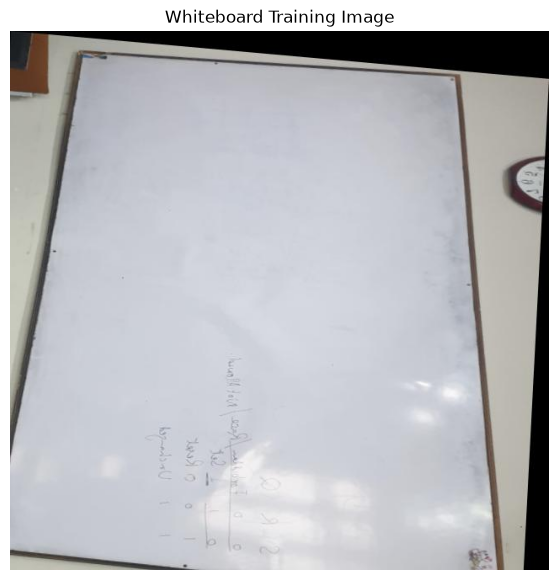

Image: 1-100-_jpg.rf.8631f615f0292d6177633f1b64e2ee93.jpg
Image dimensions: (640, 640, 3)


In [8]:
image_dir = WHITEBOARD_PATH / "train" / "images"

images = [
    file for file in image_dir.iterdir()
    if file.suffix.lower() in image_extensions
]

if not images:
    raise ValueError("No images found in the training folder.")

sample_path = images[0]

image = cv2.imread(str(sample_path))

if image is None:
    raise ValueError(f"Could not read image: {sample_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Whiteboard Training Image")
plt.show()

print("Image:", sample_path.name)
print("Image dimensions:", image.shape)